In [3]:
# ============================================================
# 04_distilbert.ipynb — Fine-tune DistilBERT on Kaggle GPU
# Binary classification: Negative=0 / Positive=1
#
# Label origin: the Booking.com form itself.
#   text from Negative_Review column → label = 'Negative'
#   text from Positive_Review column → label = 'Positive'
# This is human-annotated sentiment, fully independent of scores.
#
# KAGGLE SETUP:
#   1. Upload train.csv, val.csv, test.csv as a Kaggle Dataset.
#      Required columns: text, label, score, hotel
#      Labels must be 'Positive' or 'Negative' only.
#   2. Attach via: Add data → Your Datasets → hotel-reviews-nlp
#   3. Enable GPU: Settings → Accelerator → GPU T4 x2
#   4. Run all cells. Download distilbert_best_final.zip at end.
# ============================================================

In [4]:
import os, gc, shutil
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.nn import CrossEntropyLoss
from transformers import (
    DistilBertTokenizer,
    DistilBertForSequenceClassification,
    get_linear_schedule_with_warmup
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import FileLink, display
import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device        :", device)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU           :", torch.cuda.get_device_name(0))
    print("GPU RAM       :", round(torch.cuda.get_device_properties(0).total_memory/1e9, 1), "GB")

Device        : cuda
CUDA available: True
GPU           : Tesla T4
GPU RAM       : 15.6 GB


In [5]:
# ── 1. LOAD DATA ─────────────────────────────────────────────
DATA_PATH = '/kaggle/input/datasets/sarahdje/hotel-reviews-nlp-3'

train_df = pd.read_csv(f'{DATA_PATH}/train.csv').dropna(subset=['bert_text']).reset_index(drop=True)
val_df   = pd.read_csv(f'{DATA_PATH}/val.csv').dropna(subset=['bert_text']).reset_index(drop=True)
test_df  = pd.read_csv(f'{DATA_PATH}/test.csv').dropna(subset=['bert_text']).reset_index(drop=True)

print(f"Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")
print("Columns:", list(train_df.columns))
print("\nLabel distribution (train):")
print(train_df['label'].value_counts())
print("\nSample:")
print(train_df[['bert_text', 'label']].head(3).to_string())

Train: 496,519 | Val: 106,397 | Test: 106,397
Columns: ['clean_text', 'bert_text', 'label']

Label distribution (train):
label
Positive    279617
Negative    216902
Name: count, dtype: int64

Sample:
                                                                                                                                                                                                                       bert_text     label
0                                                                                                                               Brilliant location Right in the centre of London Staff are very nice and helpful Will stay again  Positive
1                                                                                                                                                                                                   bad wifi price is not worthy  Negative
2  We could not workout how to use air conditioner and the air was a bit dusty so had to open t

In [6]:
# ── 2. ENCODE LABELS ─────────────────────────────────────────
label2id = {'Negative': 0, 'Positive': 1}
id2label  = {0: 'Negative', 1: 'Positive'}

for df in [train_df, val_df, test_df]:
    df['label_id'] = df['label'].map(label2id)

train_df = train_df.dropna(subset=['label_id']).reset_index(drop=True)
val_df   = val_df.dropna(subset=['label_id']).reset_index(drop=True)
test_df  = test_df.dropna(subset=['label_id']).reset_index(drop=True)

train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)

# 400k is the sweet spot for Kaggle free T4:
# more data than 200k → better performance
# stays under 12h session limit at batch_size=32, 3 epochs
TRAIN_SAMPLE_SIZE = min(400_000, len(train_df))

train_sample, _ = train_test_split(
    train_df,
    train_size=TRAIN_SAMPLE_SIZE,
    stratify=train_df['label_id'],
    random_state=42
)
train_sample = train_sample.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Training sample: {len(train_sample):,} rows")
counts = train_sample['label_id'].value_counts().sort_index()
for lid, count in counts.items():
    print(f"  {id2label[lid]:<12} {count:,}  ({count/len(train_sample)*100:.1f}%)")

Training sample: 400,000 rows
  Negative     174,738  (43.7%)
  Positive     225,262  (56.3%)


In [7]:
# ── 3. CLASS WEIGHTS ─────────────────────────────────────────
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=train_sample['label_id'].values
)
class_weights = torch.tensor(weights, dtype=torch.float).to(device)

print("Class weights:")
for label, w in zip(['Negative', 'Positive'], weights):
    print(f"  {label:<12} {w:.4f}")

Class weights:
  Negative     1.1446
  Positive     0.8879


In [8]:
# ── 4. DATASET & TOKENIZER — use bert_text, NOT clean_text ───
# bert_text preserves natural English grammar that DistilBERT needs.
# clean_text is lemmatized and stripped — designed for BoW/TF-IDF only.
MODEL_NAME = 'distilbert-base-uncased'
MAX_LENGTH = 128

tokenizer = DistilBertTokenizer.from_pretrained(MODEL_NAME)

class HotelReviewDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=MAX_LENGTH):
        self.texts      = texts.tolist()
        self.labels     = labels.tolist()
        self.tokenizer  = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            str(self.texts[idx]),
            max_length=self.max_length,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        return {
            'input_ids'     : encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels'        : torch.tensor(self.labels[idx], dtype=torch.long)
        }

# NOTE: bert_text column, not text or clean_text
train_dataset = HotelReviewDataset(train_sample['bert_text'], train_sample['label_id'], tokenizer)
val_dataset   = HotelReviewDataset(val_df['bert_text'],       val_df['label_id'],       tokenizer)
test_dataset  = HotelReviewDataset(test_df['bert_text'],      test_df['label_id'],      tokenizer)

print(f"Train: {len(train_dataset):,} | Val: {len(val_dataset):,} | Test: {len(test_dataset):,}")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Train: 400,000 | Val: 106,397 | Test: 106,397


In [9]:
# ── 5. DATALOADERS ───────────────────────────────────────────
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train batches: {len(train_loader):,} | Val: {len(val_loader):,} | Test: {len(test_loader):,}")

Train batches: 12,500 | Val: 3,325 | Test: 3,325


In [10]:
# ── 6. MODEL & OPTIMIZER ─────────────────────────────────────
EPOCHS       = 3
total_steps  = len(train_loader) * EPOCHS
warmup_steps = total_steps // 10

model = DistilBertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
)
model.to(device)

optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
loss_fn   = CrossEntropyLoss(weight=class_weights)
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

gc.collect()
torch.cuda.empty_cache()

print(f"Model ready on {device}")
print(f"Labels: {id2label}")
print(f"Total steps: {total_steps:,} | Warmup: {warmup_steps:,}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model ready on cuda
Labels: {0: 'Negative', 1: 'Positive'}
Total steps: 37,500 | Warmup: 3,750


In [11]:
# ── 7. TRAINING LOOP ─────────────────────────────────────────
CKPT_DIR   = '/kaggle/working/checkpoints'
OUTPUT_DIR = '/kaggle/working'
os.makedirs(CKPT_DIR, exist_ok=True)

history     = {'train_loss': [], 'val_loss': [], 'val_f1': []}
best_f1     = 0
best_epoch  = 0
label_names = ['Negative', 'Positive']

for epoch in range(EPOCHS):

    # ── TRAIN ──────────────────────────────────────────────
    model.train()
    total_train_loss = 0

    for batch_idx, batch in enumerate(train_loader):
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        loss    = loss_fn(outputs.logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        total_train_loss += loss.item()

        if (batch_idx + 1) % 200 == 0:
            avg = total_train_loss / (batch_idx + 1)
            print(f"  Epoch {epoch+1} | Batch {batch_idx+1:,}/{len(train_loader):,} | Loss: {avg:.4f}")

    avg_train_loss = total_train_loss / len(train_loader)

    # ── VALIDATE ───────────────────────────────────────────
    model.eval()
    total_val_loss  = 0
    all_preds       = []
    all_labels_list = []

    with torch.no_grad():
        for batch in val_loader:
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['labels'].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            loss    = loss_fn(outputs.logits, labels)
            total_val_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels_list.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)
    val_f1       = f1_score(all_labels_list, all_preds, average='macro')

    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['val_f1'].append(val_f1)

    print(f"\nEpoch {epoch+1}/{EPOCHS} complete")
    print(f"  Train Loss    : {avg_train_loss:.4f}")
    print(f"  Val Loss      : {avg_val_loss:.4f}")
    print(f"  Val F1 (macro): {val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1    = val_f1
        best_epoch = epoch + 1

    ckpt_path = f'{CKPT_DIR}/epoch_{epoch+1}'
    os.makedirs(ckpt_path, exist_ok=True)
    model.save_pretrained(ckpt_path)
    tokenizer.save_pretrained(ckpt_path)

    zip_path = f'{OUTPUT_DIR}/model_epoch_{epoch+1}'
    shutil.make_archive(zip_path, 'zip', ckpt_path)
    print(f"  Saved → {zip_path}.zip")
    display(FileLink(f'model_epoch_{epoch+1}.zip'))

    gc.collect()
    torch.cuda.empty_cache()
    print()

  Epoch 1 | Batch 200/12,500 | Loss: 0.6814
  Epoch 1 | Batch 400/12,500 | Loss: 0.5532
  Epoch 1 | Batch 600/12,500 | Loss: 0.4230
  Epoch 1 | Batch 800/12,500 | Loss: 0.3553
  Epoch 1 | Batch 1,000/12,500 | Loss: 0.3113
  Epoch 1 | Batch 1,200/12,500 | Loss: 0.2805
  Epoch 1 | Batch 1,400/12,500 | Loss: 0.2587
  Epoch 1 | Batch 1,600/12,500 | Loss: 0.2408
  Epoch 1 | Batch 1,800/12,500 | Loss: 0.2270
  Epoch 1 | Batch 2,000/12,500 | Loss: 0.2154
  Epoch 1 | Batch 2,200/12,500 | Loss: 0.2070
  Epoch 1 | Batch 2,400/12,500 | Loss: 0.2001
  Epoch 1 | Batch 2,600/12,500 | Loss: 0.1934
  Epoch 1 | Batch 2,800/12,500 | Loss: 0.1883
  Epoch 1 | Batch 3,000/12,500 | Loss: 0.1835
  Epoch 1 | Batch 3,200/12,500 | Loss: 0.1786
  Epoch 1 | Batch 3,400/12,500 | Loss: 0.1757
  Epoch 1 | Batch 3,600/12,500 | Loss: 0.1720
  Epoch 1 | Batch 3,800/12,500 | Loss: 0.1693
  Epoch 1 | Batch 4,000/12,500 | Loss: 0.1664
  Epoch 1 | Batch 4,200/12,500 | Loss: 0.1634
  Epoch 1 | Batch 4,400/12,500 | Loss: 0.1

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Saved → /kaggle/working/model_epoch_1.zip


/kaggle/working/model_epoch_1.zip


  Epoch 2 | Batch 200/12,500 | Loss: 0.0728
  Epoch 2 | Batch 400/12,500 | Loss: 0.0753
  Epoch 2 | Batch 600/12,500 | Loss: 0.0771
  Epoch 2 | Batch 800/12,500 | Loss: 0.0755
  Epoch 2 | Batch 1,000/12,500 | Loss: 0.0757
  Epoch 2 | Batch 1,200/12,500 | Loss: 0.0755
  Epoch 2 | Batch 1,400/12,500 | Loss: 0.0746
  Epoch 2 | Batch 1,600/12,500 | Loss: 0.0747
  Epoch 2 | Batch 1,800/12,500 | Loss: 0.0736
  Epoch 2 | Batch 2,000/12,500 | Loss: 0.0743
  Epoch 2 | Batch 2,200/12,500 | Loss: 0.0737
  Epoch 2 | Batch 2,400/12,500 | Loss: 0.0737
  Epoch 2 | Batch 2,600/12,500 | Loss: 0.0739
  Epoch 2 | Batch 2,800/12,500 | Loss: 0.0742
  Epoch 2 | Batch 3,000/12,500 | Loss: 0.0741
  Epoch 2 | Batch 3,200/12,500 | Loss: 0.0738
  Epoch 2 | Batch 3,400/12,500 | Loss: 0.0739
  Epoch 2 | Batch 3,600/12,500 | Loss: 0.0739
  Epoch 2 | Batch 3,800/12,500 | Loss: 0.0741
  Epoch 2 | Batch 4,000/12,500 | Loss: 0.0743
  Epoch 2 | Batch 4,200/12,500 | Loss: 0.0743
  Epoch 2 | Batch 4,400/12,500 | Loss: 0.

...

/kaggle/working/model_epoch_2.zip


  Epoch 3 | Batch 200/12,500 | Loss: 0.0537
  Epoch 3 | Batch 400/12,500 | Loss: 0.0542
  Epoch 3 | Batch 600/12,500 | Loss: 0.0541
  Epoch 3 | Batch 800/12,500 | Loss: 0.0526
  Epoch 3 | Batch 1,000/12,500 | Loss: 0.0533
  Epoch 3 | Batch 1,200/12,500 | Loss: 0.0530
  Epoch 3 | Batch 1,400/12,500 | Loss: 0.0531
  Epoch 3 | Batch 1,600/12,500 | Loss: 0.0542
  Epoch 3 | Batch 1,800/12,500 | Loss: 0.0544
  Epoch 3 | Batch 2,000/12,500 | Loss: 0.0549
  Epoch 3 | Batch 2,200/12,500 | Loss: 0.0544
  Epoch 3 | Batch 2,400/12,500 | Loss: 0.0537
  Epoch 3 | Batch 2,600/12,500 | Loss: 0.0542
  Epoch 3 | Batch 2,800/12,500 | Loss: 0.0549
  Epoch 3 | Batch 3,000/12,500 | Loss: 0.0551
  Epoch 3 | Batch 3,200/12,500 | Loss: 0.0556
  Epoch 3 | Batch 3,400/12,500 | Loss: 0.0556
  Epoch 3 | Batch 3,600/12,500 | Loss: 0.0556
  Epoch 3 | Batch 3,800/12,500 | Loss: 0.0561
  Epoch 3 | Batch 4,000/12,500 | Loss: 0.0563
  Epoch 3 | Batch 4,200/12,500 | Loss: 0.0563
  Epoch 3 | Batch 4,400/12,500 | Loss: 0.

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Saved → /kaggle/working/model_epoch_3.zip


/kaggle/working/model_epoch_3.zip

In [12]:
# ── 8. TEST SET EVALUATION ───────────────────────────────────
# We collect full softmax probabilities, not just predicted class.
# P(Positive) is the confidence score used later in the recommendation.
print("Running test evaluation...")
model.eval()
all_probs       = []
all_preds       = []
all_labels_list = []

with torch.no_grad():
    for batch in test_loader:
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)

        # softmax → probabilities for [Negative, Positive]
        probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)

        all_probs.extend(probs.tolist())
        all_preds.extend(preds.tolist())
        all_labels_list.extend(labels.cpu().numpy().tolist())

prob_positive = [p[1] for p in all_probs]  # P(Positive) per review

print("="*55)
print("TEST SET RESULTS")
print("="*55)
print(f"Accuracy     : {accuracy_score(all_labels_list, all_preds):.4f}")
print(f"F1 (macro)   : {f1_score(all_labels_list, all_preds, average='macro'):.4f}")
print(f"F1 (weighted): {f1_score(all_labels_list, all_preds, average='weighted'):.4f}")
print()
print(classification_report(all_labels_list, all_preds, target_names=['Negative', 'Positive']))
print()
# Confidence breakdown — shows the model is not just flipping coins
high   = sum(p > 0.9 or p < 0.1 for p in prob_positive)
medium = sum((0.7 < p <= 0.9) or (0.1 <= p < 0.3) for p in prob_positive)
low    = sum((0.5 <= p <= 0.7) or (0.3 <= p < 0.5) for p in prob_positive)
total  = len(prob_positive)
print("Confidence breakdown on test set:")
print(f"  High   (>90% sure) : {high:,}  ({high/total*100:.1f}%)")
print(f"  Medium (70-90%)    : {medium:,}  ({medium/total*100:.1f}%)")
print(f"  Low    (50-70%)    : {low:,}  ({low/total*100:.1f}%)")

Running test evaluation...
TEST SET RESULTS
Accuracy     : 0.9737
F1 (macro)   : 0.9733
F1 (weighted): 0.9737

              precision    recall  f1-score   support

    Negative       0.96      0.98      0.97     46479
    Positive       0.98      0.97      0.98     59918

    accuracy                           0.97    106397
   macro avg       0.97      0.97      0.97    106397
weighted avg       0.97      0.97      0.97    106397


Confidence breakdown on test set:
  High   (>90% sure) : 104,572  (98.3%)
  Medium (70-90%)    : 1,237  (1.2%)
  Low    (50-70%)    : 588  (0.6%)


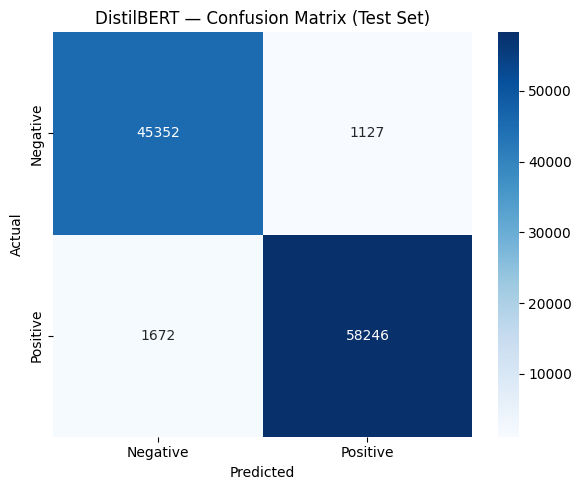

/kaggle/working/confusion_matrix_distilbert.png

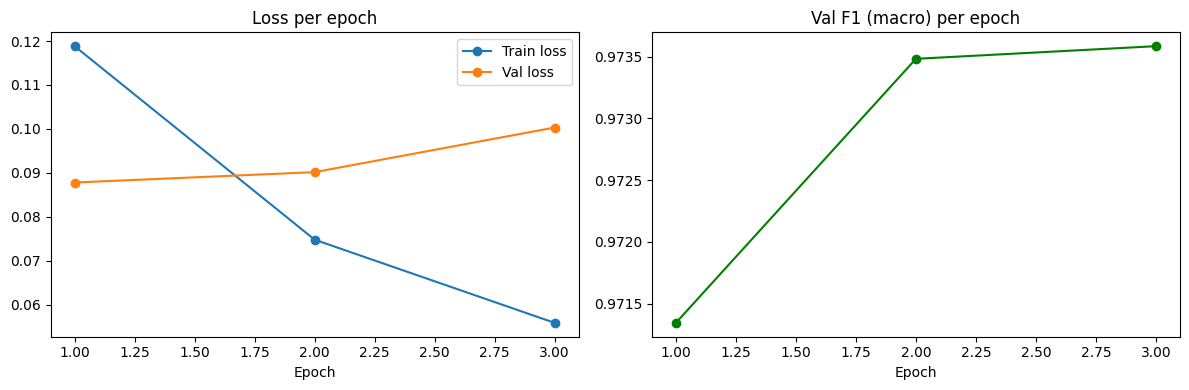

/kaggle/working/training_curve_distilbert.png

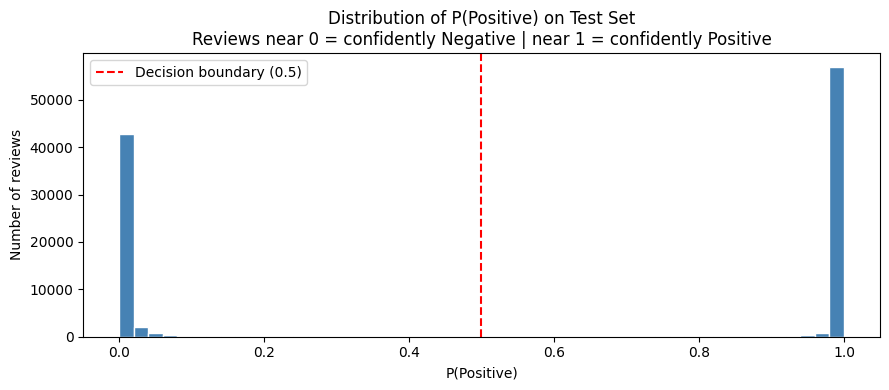

/kaggle/working/confidence_distribution.png

In [13]:
# ── 9. PLOTS ─────────────────────────────────────────────────
label_names = ['Negative', 'Positive']

# Confusion matrix
cm = confusion_matrix(all_labels_list, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('DistilBERT — Confusion Matrix (Test Set)')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/confusion_matrix_distilbert.png', dpi=150)
plt.show()
display(FileLink('confusion_matrix_distilbert.png'))

# Training curves
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_range, history['train_loss'], 'o-', label='Train loss')
axes[0].plot(epochs_range, history['val_loss'],   'o-', label='Val loss')
axes[0].set_title('Loss per epoch')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[1].plot(epochs_range, history['val_f1'], 'o-', color='green')
axes[1].set_title('Val F1 (macro) per epoch')
axes[1].set_xlabel('Epoch')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/training_curve_distilbert.png', dpi=150)
plt.show()
display(FileLink('training_curve_distilbert.png'))

# P(Positive) distribution — key diagnostic plot
# A good model pushes most reviews to the extremes (near 0 or near 1)
# A weak model would cluster everything around 0.5
plt.figure(figsize=(9, 4))
plt.hist(prob_positive, bins=50, color='steelblue', edgecolor='white')
plt.axvline(0.5, color='red', linestyle='--', label='Decision boundary (0.5)')
plt.title('Distribution of P(Positive) on Test Set\n'
          'Reviews near 0 = confidently Negative | near 1 = confidently Positive')
plt.xlabel('P(Positive)')
plt.ylabel('Number of reviews')
plt.legend()
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/confidence_distribution.png', dpi=150)
plt.show()
display(FileLink('confidence_distribution.png'))

In [ ]:
# ── 10. SAVE BEST MODEL ──────────────────────────────────────
best_ckpt = f'{CKPT_DIR}/epoch_{best_epoch}'
shutil.make_archive(f'{OUTPUT_DIR}/distilbert_best_final', 'zip', best_ckpt)
print(f"Best model: epoch {best_epoch} — Val F1: {best_f1:.4f}")
display(FileLink('distilbert_best_final.zip'))
print("^^^ Download this zip ^^^")
print()
print("NEXT STEPS:")
print("  1. Unzip distilbert_best_final.zip")
print("  2. Upload its contents as a Kaggle dataset named 'distilbert-weights'")
print("     (the folder must contain config.json + model.safetensors or pytorch_model.bin)")
print("  3. Run 05_inference_kaggle.ipynb")

Best model: epoch 3 — Val F1: 0.9736


/kaggle/working/distilbert_best_final.zip

^^^ Download this zip ^^^

NEXT STEPS:
  1. Unzip distilbert_best_final.zip
  2. Upload its contents as a Kaggle dataset named 'distilbert-weights'
     (the folder must contain config.json + model.safetensors or pytorch_model.bin)
  3. Run 05_inference_kaggle.ipynb
